# 05-0b — La démoscène : l'intro comme argument de compression

**Navigation** : [← 05-0 : Générateurs symboliques](05-0-Generateurs-Symboliques.ipynb) | [↑ 05-History](README.md) | [05-1 : DiscoDiffusion →](05-1-DiscoDiffusion-CLIP-Guided-Diffusion.ipynb)

> **Notebook rétrospectif — Racines pré-Stable-Diffusion.** Deuxième jalon de
> l'[Epic #16774](https://github.com/jsboige/CoursIA/issues/16774). Il approfondit
> le [05-0](05-0-Generateurs-Symboliques.ipynb), d'où la lettre `b` : même thèse
> (une description courte engendre un rendu riche), poussée là où une
> communauté entière en a fait un sport de compétition.

**La thèse du notebook en une ligne** : une intro de démoscène n'est pas une
vidéo compressée, c'est un **programme qui fabrique la vidéo**. Nous le
vérifions par la mesure : pour chaque effet classique, le code qui le produit
est **plus court** que ce qu'un compresseur générique (LZMA) parvient à faire
des images elles-mêmes.

## 1. Un phénomène de mode des années 80-90

La démoscène naît dans les écrans d'accueil des logiciels « crackés » des
années 1980 (les *cracktros* sur Commodore 64 puis Amiga), puis s'émancipe en
une scène autonome : des groupes produisent des **démos** — animations
temps réel, son compris — et se mesurent dans des compétitions lors de
*demoparties* (Assembly en Finlande, The Party au Danemark, puis Breakpoint et
Revision en Allemagne).

Quelques jalons souvent cités, que l'on retrouve dans toute histoire de la scène :

| Production | Groupe | Année, party | Ce qu'elle montre |
|---|---|---|---|
| *Second Reality* | Future Crew | 1993, Assembly | la démo PC de référence de l'ère DOS : plasma, tunnels, rotozoom, scènes 3D |
| *fr-08: .the .product* | Farbrausch | 2000, The Party | une démo complète dans **64 ko** : textures, maillages et musique générés au lancement |
| *.kkrieger* | .theprodukkt | 2004, Breakpoint | un jeu de tir à la première personne jouable dans **96 ko** |
| *Elevated* | Rgba & TBC | 2009, Breakpoint | des paysages montagneux en **4 ko** (4096 octets) |

Les catégories de compétition (64k, 4k, et même 1k ou 256 octets) fixent une
**borne sur la taille de l'exécutable**. C'est exactement une borne sur la
longueur de description : la scène a fait de la compression un critère
esthétique, une décennie avant que Schmidhuber ne théorise le
*low-complexity art* (jalon 3 de l'Epic).

La suite du notebook rejoue les **effets canoniques** de l'ère DOS en NumPy, à
la résolution du mode VGA 13h (320×200, 256 couleurs indexées), et mesure à
chaque fois la longueur du programme face au poids des images.

In [1]:
import inspect
import lzma
import time

import matplotlib.pyplot as plt
import numpy as np

W, H = 320, 200          # mode VGA 13h : 320x200, un octet par pixel
N_FRAMES = 64            # longueur de chaque sequence mesuree
y, x = np.mgrid[0:H, 0:W].astype(np.float32)

def palette_demo():
    # Palette 256 couleurs construite par des sinus decales -- l'astuce d'epoque :
    # trois canaux sinusoidaux donnent un degrade cyclique sans table stockee.
    t = np.linspace(0, 2 * np.pi, 256, endpoint=False)
    rgb = np.stack([0.5 + 0.5 * np.sin(t), 0.5 + 0.5 * np.sin(t + 2.1),
                    0.5 + 0.5 * np.sin(t + 4.2)], axis=1)
    return rgb

PALETTE = palette_demo()

def montrer(frames, titre, indices=(0, 16, 32, 48), palette=PALETTE):
    # Affiche quelques frames d'une sequence indexee (uint8) via la palette.
    fig, axes = plt.subplots(1, len(indices), figsize=(3.2 * len(indices), 2.4))
    for ax, i in zip(axes, indices):
        ax.imshow(palette[frames[i]], interpolation='nearest')
        ax.set_title(f't = {i}'); ax.axis('off')
    fig.suptitle(titre)
    plt.tight_layout(); plt.show()

print(f"Resolution {W}x{H}, {N_FRAMES} frames -> {W * H * N_FRAMES:,} octets bruts par sequence")

Resolution 320x200, 64 frames -> 4,096,000 octets bruts par sequence


## 2. Le plasma : une somme de sinus et une palette

Le **plasma** est l'effet emblématique de l'ère DOS. Chaque pixel reçoit une
somme de sinus de ses coordonnées et du temps ; l'animation vient du terme
temporel et, à l'époque, souvent du simple **cycle de palette** (faire tourner
la table des couleurs sans toucher aux pixels). Aucune image n'est stockée :
la fonction est l'image.

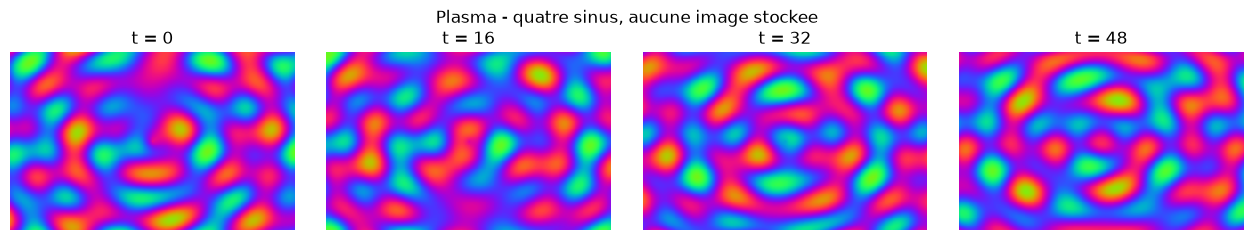

In [2]:
def plasma(t):
    v = (np.sin(x / 16 + t / 8) + np.sin(y / 8 + t / 12)
         + np.sin((x + y + t) / 16) + np.sin(np.hypot(x - W / 2, y - H / 2) / 8 - t / 6))
    return ((v + 4) * 32).astype(np.uint8)

frames_plasma = np.stack([plasma(t) for t in range(N_FRAMES)])
montrer(frames_plasma, 'Plasma - quatre sinus, aucune image stockee')

### Interprétation : quatre sinus suffisent

Les quatre frames montrent des volutes colorées qui se déforment d'un instant
à l'autre : deux ondes planes, une onde diagonale et une onde **radiale**
centrée sur l'écran, dont les anneaux se devinent autour du centre. La
richesse apparente vient de l'**interférence** entre ces quatre termes et du
repliement par la palette cyclique (256 valeurs pour un signal qui en parcourt
plusieurs tours). Le code tient en trois lignes ; la séquence produite pèse déjà 4 Mo en brut (320×200×64 = 4 096 000 octets — valeur calculée en cellule de setup, l'output de la cellule plasma ci-dessus ne porte pas ce chiffre).

## 3. Le tunnel : deux tables précalculées et une texture

Le **tunnel** est l'archétype du *précalcul* démoscénique : pour chaque pixel
on calcule une seule fois sa distance au centre et son angle, qui deviennent
des coordonnées de texture. À chaque frame, il ne reste qu'à **décaler** ces
coordonnées : le coût par frame tombe à une lecture de table, ce qui rendait
l'effet fluide sur un 486. La texture elle-même est générée (un motif XOR,
autre classique de l'époque).

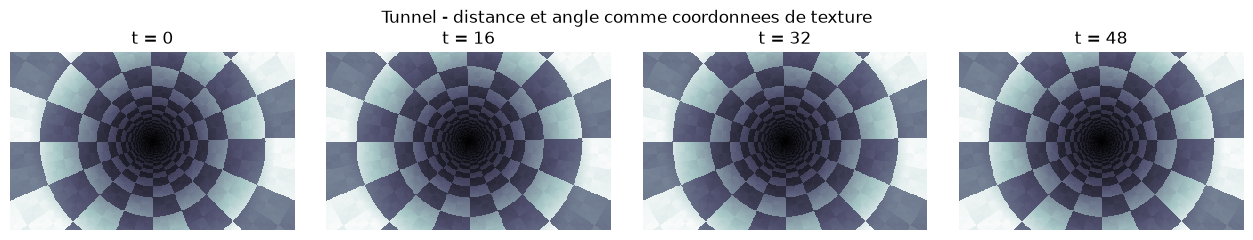

In [3]:
def tunnel(t):
    dx, dy = x - W / 2, y - H / 2
    r = np.hypot(dx, dy) + 1
    u = (4096 / r).astype(np.int32) + 4 * t                        # profondeur
    v = (128 * np.arctan2(dy, dx) / np.pi).astype(np.int32) + 2 * t  # angle
    damier = ((u >> 4) ^ (v >> 4)) & 1                              # texture generee
    texture = 120 + 100 * damier + ((u ^ v) & 31)
    ombre = np.clip(r / 140, 0, 1)                                   # le fond s'eteint
    return (texture * ombre).astype(np.uint8)

PALETTE_GRIS = plt.cm.bone(np.arange(256))[:, :3]   # palette monotone : 0 = noir
frames_tunnel = np.stack([tunnel(t) for t in range(N_FRAMES)])
montrer(frames_tunnel, 'Tunnel - distance et angle comme coordonnees de texture', palette=PALETTE_GRIS)

### Interprétation : la perspective vient d'une division

On voit un couloir qui file vers le centre : les cases du damier s'écrasent
en anneaux de plus en plus serrés près du point de fuite, et le noir central
donne la profondeur. Toute la perspective tient dans la division `4096 / r` :
un pixel proche du centre lit une case « lointaine ». D'une frame à l'autre,
la texture glisse (terme `4 * t` sur la profondeur, `2 * t` sur l'angle) et
le tunnel semble avancer en tournant. L'assombrissement exige une palette
**monotone** (ici du noir au blanc) : avec la palette cyclique du plasma,
multiplier un indice par `ombre` ne l'assombrirait pas, il changerait sa teinte.

## 4. Le feu : un automate cellulaire déguisé

L'effet **feu** est un cousin direct des automates du [05-0](05-0-Generateurs-Symboliques.ipynb) :
on allume aléatoirement la ligne du bas, puis chaque pixel devient la moyenne
de ses voisins du dessous, légèrement refroidie. La règle est **locale** et
appliquée partout : c'est un automate cellulaire à états continus. Le hasard
est piloté par une graine, qui fait partie de la description.

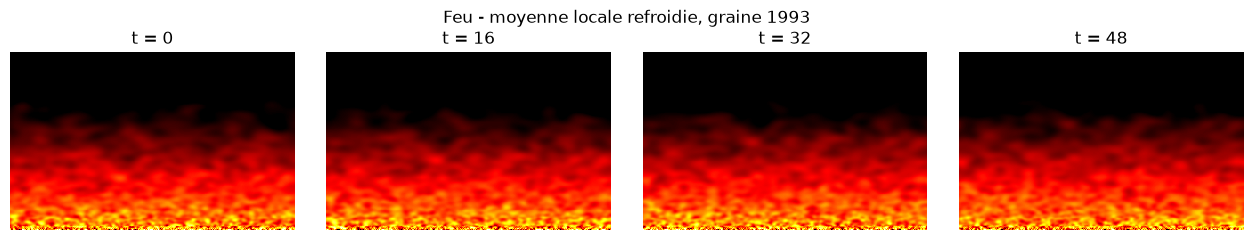

In [4]:
def feu(n_frames, graine=1993):
    rng = np.random.default_rng(graine)
    f = np.zeros((H + 2, W), dtype=np.float32)
    sortie = []
    for _ in range(n_frames + 200):           # 200 frames de chauffe
        f[-2:] = 255 * (rng.random((2, W)) < 0.55)   # le foyer : braises au hasard
        moyenne = (f[2:] + np.roll(f[1:-1], 1, 1) + f[1:-1] + np.roll(f[1:-1], -1, 1)) / 4
        f[:-2] = np.maximum(moyenne - 1.3, 0)          # refroidissement
        sortie.append(f[:H].astype(np.uint8))
    return np.stack(sortie[200:])

PALETTE_FEU = np.stack([np.clip(np.arange(256) / 85, 0, 1),
                        np.clip(np.arange(256) / 85 - 1, 0, 1),
                        np.clip(np.arange(256) / 85 - 2, 0, 1)], axis=1)
frames_feu = feu(N_FRAMES)
montrer(frames_feu, 'Feu - moyenne locale refroidie, graine 1993', palette=PALETTE_FEU)

### Interprétation : flammes, sans une ligne sur les flammes

Les flammes montent depuis le bas de l'écran et s'éteignent vers le haut,
avec des langues irrégulières différentes à chaque frame. Le code ne dit rien
des flammes : il dit seulement « allume le bas au hasard, puis fais la moyenne
des voisins en refroidissant un peu » (le terme `- 1.3`). La hauteur des
flammes est fixée par ce seul refroidissement : plus il est fort, plus le feu
s'éteint bas. La
forme émerge de la règle locale, exactement comme le planeur du Game of Life ;
la palette noir → rouge → jaune → blanc fait le reste.

## 5. Le rotozoom : une texture, une matrice

Le **rotozoomer** applique à chaque frame une rotation et un facteur d'échelle
à une texture répétée à l'infini. Sur Amiga et PC, c'était l'effet
« impossible » du début des années 90 : il exige de recalculer chaque pixel à
chaque frame, d'où des boucles internes en assembleur réduites à deux
additions par pixel. En NumPy, c'est une transformation affine des
coordonnées.

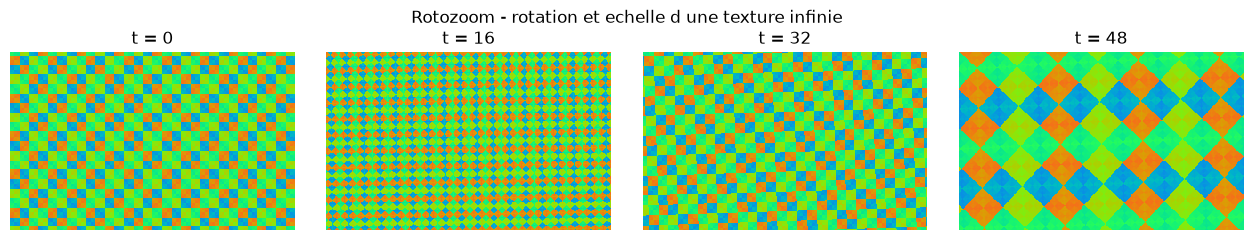

In [5]:
def rotozoom(t):
    a, zoom = t / 20, 1.5 + np.sin(t / 10)
    u = ((x - W / 2) * np.cos(a) - (y - H / 2) * np.sin(a)) * zoom
    v = ((x - W / 2) * np.sin(a) + (y - H / 2) * np.cos(a)) * zoom
    ui, vi = u.astype(np.int32), v.astype(np.int32)
    damier = ((ui >> 4) ^ (vi >> 4)) & 1
    return (damier * 160 + ((ui ^ vi) & 63)).astype(np.uint8)

frames_roto = np.stack([rotozoom(t) for t in range(N_FRAMES)])
montrer(frames_roto, 'Rotozoom - rotation et echelle d une texture infinie')

### Interprétation : le mouvement est dans la matrice

Les quatre frames montrent le même damier texturé, tourné d'un angle
croissant et zoomé selon un sinus : l'image ne change pas, c'est le **repère**
qui bouge. Le coût de l'effet est proportionnel au nombre de pixels et non à
la complexité de la texture, d'où son attrait à l'époque : une seule
transformation donne l'illusion d'une caméra libre au-dessus d'un sol infini.

## 6. Le raymarching : la scène 4k des années 2000

À partir des années 2000, les intros 4k basculent sur le GPU et une technique
domine : le **raymarching de champs de distance signée** (*signed distance
fields*, SDF), popularisé dans la scène par Iñigo Quílez (Rgba, coauteur
d'*Elevated*). La scène n'est plus une liste de triangles mais une **fonction**
qui rend, pour tout point de l'espace, sa distance à la surface la plus proche.
On avance le long de chaque rayon d'un pas égal à cette distance, en sécurité,
jusqu'à toucher la surface.

Ci-dessous, une scène complète (sol, sphères répétées à l'infini par un
modulo, éclairage diffus et ombre portée de brouillard) en une trentaine de
lignes, rendue sur CPU à demi-résolution pour rester raisonnable.

64 frames raymarchees en 5.0 s (CPU, 160x100)


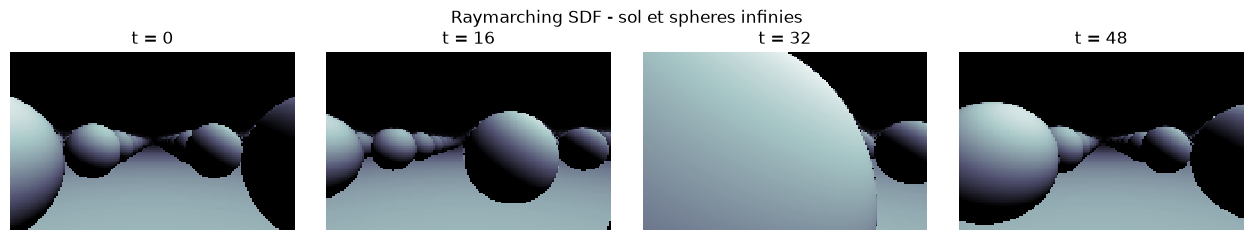

In [6]:
def scene_sdf(px, py, pz):
    sol = py + 1.0
    cx, cz = (px % 4.0) - 2.0, (pz % 4.0) - 2.0      # repetition infinie par modulo
    spheres = np.sqrt(cx ** 2 + (py - 0.2) ** 2 + cz ** 2) - 0.9
    return np.minimum(sol, spheres)

def raymarch(t, w=W // 2, h=H // 2, pas=64):
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    dx, dy = (xx - w / 2) / h, -(yy - h / 2) / h
    dz = np.ones_like(dx)
    n = np.sqrt(dx ** 2 + dy ** 2 + dz ** 2); dx, dy, dz = dx / n, dy / n, dz / n
    ox, oy, oz = 0.3 * t, 0.5, 0.6 * t                # la camera avance et derive
    d = np.zeros_like(dx)
    for _ in range(pas):
        d += scene_sdf(ox + dx * d, oy + dy * d, oz + dz * d)
    px, py, pz = ox + dx * d, oy + dy * d, oz + dz * d
    e = 1e-3                                          # normale par differences finies
    gx = scene_sdf(px + e, py, pz) - scene_sdf(px - e, py, pz)
    gy = scene_sdf(px, py + e, pz) - scene_sdf(px, py - e, pz)
    gz = scene_sdf(px, py, pz + e) - scene_sdf(px, py, pz - e)
    gn = np.sqrt(gx ** 2 + gy ** 2 + gz ** 2) + 1e-9
    lumiere = np.clip((gx * 0.5 + gy * 0.8 - gz * 0.3) / gn, 0, 1)
    brouillard = np.exp(-0.04 * d)
    return (255 * lumiere * brouillard).astype(np.uint8)

t0 = time.perf_counter()
frames_sdf = np.stack([raymarch(t / 4) for t in range(N_FRAMES)])
print(f"{N_FRAMES} frames raymarchees en {time.perf_counter() - t0:.1f} s (CPU, {W // 2}x{H // 2})")
montrer(frames_sdf, 'Raymarching SDF - sol et spheres infinies', palette=PALETTE_GRIS)

### Interprétation : une scène infinie décrite par un `min`

Les frames montrent une forêt de sphères alignées à perte de vue sur un sol,
éclairées par le haut et noyées dans le brouillard au loin ; la caméra avance
d'une frame à l'autre. Tout tient dans `scene_sdf` : le `min` fait l'union
des objets et le modulo répète les sphères **à l'infini** sans en stocker
aucune. C'est la forme moderne de la thèse du jalon : une scène dont la
description fait quelques centaines d'octets et dont le rendu n'a pas de
borne. Le temps de calcul affiché (CPU, NumPy) rappelle pourquoi ces intros
ciblent le GPU, où le même code tourne par pixel en parallèle.

## 7. La mesure : le programme contre le compresseur

C'est la leçon exécutable du jalon. Pour chaque effet, on compare trois
grandeurs :

- **le rendu brut** : la séquence de 64 frames, un octet par pixel ;
- **les frames compressées par LZMA** (`preset=9 | PRESET_EXTREME`) : ce que
  fait un bon compresseur générique, qui ne sait rien de la façon dont les
  images ont été produites ;
- **le programme compressé** : le code source de la fonction d'effet, lui
  aussi passé par LZMA. C'est l'équivalent du *packer* d'exécutable des
  intros 4k et 64k.

**Ce que la mesure compte, et ce qu'elle ne compte pas.** La cellule
mesure uniquement la **source des noyaux** (`inspect.getsource(f)` pour
chaque fonction d'effet), et le ratio `frames/source-de-noyaux` est ce
qui figure dans la colonne `brut/prog` du tableau ci-dessous — c'est la
métrique centrale de cette section. Sont **exclus explicitement** de la
mesure :

- les **dimensions** `W` et `H` de l'image (320×200 pour plasma / tunnel / feu / rotozoom, et 160×100 pour le raymarching rendu à demi-résolution, comme annoncé en section 6).
- les **coordonnées et offsets** : `x`, `y` (positions initiales,
  déphasages, centres de rotation) ;
- la **palette** de couleurs (les LUT et gradients) ;
- les **paramètres** algorithmiques (vitesses, amplitudes, fréquences,
  coefficients d'amortissement) ;
- l'**assemblage** de la fonction (imports, fermetures, environnement
  d'appel, conditions initiales) ;
- l'**interpréteur Python, NumPy et matplotlib** — une intro réelle ne
  les a pas non plus (elle s'appuie sur le système, les pilotes et
  parfois DirectX ou OpenGL, mais doit embarquer tout le reste).

Le chiffre mesure donc une description **relative à un langage, une
palette et un jeu de paramètres donnés** : le ratio dépend de la
représentation choisie, sans invariance ni borne de complexité
démontrée. La mesure n'établit rien sur la complexité d'un effet
**arbitraire** en dehors de l'instance précise mesurée — c'est ce
que la section 8 vérifie empiriquement en faisant varier le nombre
de frames.


In [7]:
def taille_lzma(donnees):
    return len(lzma.compress(donnees, preset=9 | lzma.PRESET_EXTREME))

effets = {
    'plasma': (plasma, frames_plasma),
    'tunnel': (tunnel, frames_tunnel),
    'feu': (feu, frames_feu),
    'rotozoom': (rotozoom, frames_roto),
    'raymarching': ([scene_sdf, raymarch], frames_sdf),
}

lignes = []
for nom, (fonctions, frames) in effets.items():
    fonctions = fonctions if isinstance(fonctions, list) else [fonctions]
    source = ''.join(inspect.getsource(f) for f in fonctions).encode('utf-8')
    brut = frames.nbytes
    frames_z = taille_lzma(frames.tobytes())
    prog_z = taille_lzma(source)
    lignes.append((nom, len(source), prog_z, brut, frames_z))

print(f"{'effet':<12}{'source':>8}{'source.xz':>11}{'brut':>12}{'frames.xz':>11}"
      f"{'brut/prog':>11}{'xz/prog':>9}")
for nom, src, prog_z, brut, frames_z in lignes:
    print(f"{nom:<12}{src:>8,}{prog_z:>11,}{brut:>12,}{frames_z:>11,}"
          f"{brut / prog_z:>11,.0f}{frames_z / prog_z:>9,.1f}")

effet         source  source.xz        brut  frames.xz  brut/prog  xz/prog
plasma           205        200   4,096,000  1,092,368     20,480  5,461.8
tunnel           505        344   4,096,000    401,200     11,907  1,166.3
feu              533        404   4,096,000    906,888     10,139  2,244.8
rotozoom         349        260   4,096,000    660,928     15,754  2,542.0
raymarching    1,224        628   1,024,000    137,720      1,631    219.3


### Interprétation : le générateur bat le compresseur

La dernière colonne est la mesure qui compte : elle divise la taille que LZMA
obtient sur les frames par la taille du programme compressé.

- Les **ratios bruts** (avant-dernière colonne) vont d'environ ×1 600 pour le
  raymarching (frames à demi-résolution, programme le plus long) à ×20 000 pour
  le plasma, dont le programme tient en 200 octets compressés. C'est l'ordre de
  grandeur du 05-0, sur des séquences animées au lieu d'images fixes.
- LZMA, lui, ne gagne qu'un facteur **3,7 à 10** sur le rendu brut. Le programme
  reste donc de **plus de 200 fois** (raymarching) à **plus de 5 000 fois**
  (plasma) plus court que les frames les mieux compressées. LZMA ne voit qu'une
  suite d'octets et ne peut exploiter que des répétitions ; il ne peut pas
  retrouver « somme de quatre sinus » à partir des pixels.
- Le classement contredit l'intuition visuelle. Le plasma, l'effet le plus
  simple à écrire, est celui que LZMA compresse le **moins bien** (facteur 3,7) :
  ses dégradés lisses changent de valeur à chaque pixel, sans motif répété
  octet pour octet. À l'inverse, le tunnel est le mieux compressé (facteur 10) :
  son damier produit de longues plages de valeurs identiques. Le feu, nourri de
  hasard, se situe entre les deux (facteur 4,5) ; son hasard coûte cher à LZMA,
  alors que dans le programme il tient en une graine de quatre chiffres.

« Simple » ne veut donc pas dire la même chose pour un humain, pour un
compresseur et pour un programme.

La **théorie générale** de la complexité de Kolmogorov définit la complexité
d'un objet comme
la longueur du plus court programme qui le produit ;
un compresseur générique
n'en donne qu'une **borne supérieure**, souvent
lâche.

Ce que mesurent les cinq colonnes du tableau ci-dessus n'est **pas** une borne de
la complexité de Kolmogorov des effets : les cinq noyaux rejoués ici sont
**non autonomes** — chaque frame est calculée à l'exécution à partir de
l'indice de temps, des paramètres et des coordonnées, hors du texte source.
La colonne « taille du programme » capture donc la source des noyaux extraite
par `inspect.getsource` (dimensions, coordonnées, paramètres, boucles,
interpréteur et NumPy **exclus**), et **non** un générateur autonome complet
de la séquence d'images. La comparaison « octets du programme vs octets des frames »
reste donc **descriptive** et ne devient pas une borne théorique de la complexité
de Kolmogorov : la même chaîne d'octets, face à un noyau différent ou à un état initial
varié, produirait un objet différent, et la complexité mesurée se déplacerait
avec.


Le jalon 3 de l'Epic (Schmidhuber, *low-complexity art*) part de la théorie générale
pour en faire un art dont la description est courte.

## 8. Le ratio grandit avec la durée

Un dernier contrôle rend la thèse quantitative. La description d'un effet est
**constante** ; le rendu, lui, croît avec le nombre de frames
— c'est l'observation conduite sur 8 à 128 frames en §8, pas une loi
générale au-delà de ce domaine.
LZMA, de son côté, profite de la ressemblance entre frames successives, mais
doit tout de même encoder ce qui change. On mesure les deux sur le plasma pour
des séquences de plus en plus longues.

   8 frames : brut    512,000 o | frames.xz   161,988 o | programme.xz 200 o | xz/programme x810
  16 frames : brut  1,024,000 o | frames.xz   301,284 o | programme.xz 200 o | xz/programme x1,506
  32 frames : brut  2,048,000 o | frames.xz   572,408 o | programme.xz 200 o | xz/programme x2,862
  64 frames : brut  4,096,000 o | frames.xz 1,092,368 o | programme.xz 200 o | xz/programme x5,462
 128 frames : brut  8,192,000 o | frames.xz 2,086,916 o | programme.xz 200 o | xz/programme x10,435


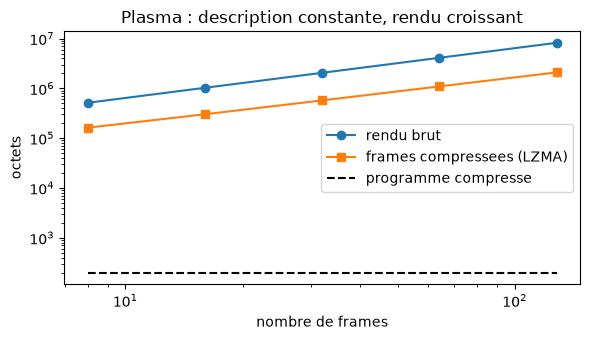

In [8]:
source_plasma = taille_lzma(inspect.getsource(plasma).encode('utf-8'))
durees = [8, 16, 32, 64, 128]
mesures = []
for n in durees:
    seq = np.stack([plasma(t) for t in range(n)])
    mesures.append((n, seq.nbytes, taille_lzma(seq.tobytes())))

for n, brut, xz in mesures:
    print(f"{n:>4} frames : brut {brut:>10,} o | frames.xz {xz:>9,} o | programme.xz {source_plasma} o"
          f" | xz/programme x{xz / source_plasma:,.0f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.loglog(durees, [m[1] for m in mesures], 'o-', label='rendu brut')
ax.loglog(durees, [m[2] for m in mesures], 's-', label='frames compressees (LZMA)')
ax.loglog(durees, [source_plasma] * len(durees), 'k--', label='programme compresse')
ax.set_xlabel('nombre de frames'); ax.set_ylabel('octets'); ax.legend()
ax.set_title('Plasma : description constante, rendu croissant')
plt.tight_layout(); plt.show()

### Interprétation : l'écart se creuse avec le temps

Sur l'échelle log-log, le rendu brut est une droite de pente 1 et la courbe
LZMA reste parallèle à elle, plus bas : le compresseur gagne un facteur à peu
près fixe mais doit payer chaque nouvelle frame. Le programme, lui, est une
droite horizontale : il ne coûte rien de plus pour une minute que pour une
seconde. C'est pourquoi une démo de plusieurs minutes peut tenir dans 64 ko
alors que la même vidéo, même bien compressée, pèserait des mégaoctets : le
rapport n'est pas un exploit ponctuel mais une **observation sur 8 à 128 frames**,
conduite sur le plasma seul. La limite 8-128 frames reste non
mesurée au-delà.

Les mesures de la section précédente le montrent : pour le plasma, le
ratio `frames-compressées / programme` passe de 810 (8 frames) à
1 506 (16 frames), 2 862 (32 frames), 5 462 (64 frames) et 10 435
(128 frames). Chaque doublement du nombre de frames s'accompagne
d'un doublement approché du ratio, soit une croissance linéaire
dans le domaine observé. Au-delà de 128 frames, la mesure n'est pas
faite ici — la limite reste non mesurée.


## 9. Exercices

Trois exercices dans l'esprit du corpus : le squelette s'exécute, la
réalisation vous appartient.

In [9]:
# Exercice 1 - votre plasma
# Modifier les frequences (les diviseurs 16, 8, 12...) ou ajouter un cinquieme terme
# sinusoidal, puis mesurer la nouvelle ligne du tableau de la section 7.
# # Indice 1 - definir plasma2(t) sur le modele de plasma(t) ;
# # Etape 1 - generer 64 frames ; # Etape 2 - comparer taille_lzma(frames) a taille_lzma(source).
print("Exercice 1 a completer")

Exercice 1 a completer


In [10]:
# Exercice 2 - un effet de plus : le champ d'etoiles
# Ecrire starfield(t) : N etoiles (x, y, z) tirees avec une graine fixe, projetees en
# perspective (x/z, y/z) et rapprochees de la camera a chaque frame.
# # Indice 1 - z diminue avec t, et revient au fond (modulo) quand il passe sous 0 ;
# # Etape 1 - generer les frames ; # Etape 2 - mesurer comme en section 7 ;
# # Etape 3 - expliquer pourquoi LZMA s'en sort ici mieux ou moins bien que sur le feu.
print("Exercice 2 a completer")

Exercice 2 a completer


In [11]:
# Exercice 3 - le budget 4k
# Concatener les sources des cinq effets et mesurer leur taille compressee par LZMA.
# Tiennent-ils dans 4096 octets ? Sinon, quel effet sacrifier en premier, et pourquoi ?
# # Indice 1 - reutiliser inspect.getsource et taille_lzma ;
# # Etape 1 - mesurer le total ; # Etape 2 - classer les effets par cout marginal.
print("Exercice 3 a completer")

Exercice 3 a completer


## 10. Conclusion

Ce jalon a rejoué cinq effets canoniques de la démoscène (plasma, tunnel, feu,
rotozoom, raymarching SDF) et mesuré ce qu'ils ont en commun : chaque fois, le
programme compressé est **plus court** que les images compressées par un
compresseur générique, et l'écart croît avec la durée. La démoscène pratiquait
la complexité de Kolmogorov avant de la nommer.

La suite du rayon :

- **jalon 3**, le *low-complexity art* de Schmidhuber : la théorie de ce que la
  scène pratiquait, l'art dont la description est courte (jointure avec
  l'[Epic #16775](https://github.com/jsboige/CoursIA/issues/16775)) ;
- **jalon 4**, les GANs : la règle cesse d'être écrite à la main pour être
  apprise ;
- [05-1](05-1-DiscoDiffusion-CLIP-Guided-Diffusion.ipynb), la CLIP-guided diffusion :
  le prompt remplace l'effet, le réseau remplace la boucle.

**Rattachements** : Epic #16774 (jalon 2) · [05-0](05-0-Generateurs-Symboliques.ipynb)
(jalon 1, dont ce notebook est l'accrétion) · Epic #16741 (fil transverse de la
longueur de description).